# Backtest del Elo

**Objetivo:** elegir K (cuánto se mueve el rating después de cada game) y el ajuste inicial de cada región.

**Método:** se corre el Elo sobre temporadas pasadas "como si fueran en vivo": la probabilidad de cada game se calcula antes de conocer su resultado.
- **Calibración:** temporada 2024 (ligas + MSI/EWC/Worlds).
- **Validación:** temporada 2025, que el modelo no vio al elegir los valores.
- **Métrica:** Brier score en games entre equipos de regiones distintas (los únicos que ponen a prueba el ajuste regional). Tirar una moneda da 0.25.

⚠️ **Muestra chica:** hay pocos cientos de games entre regiones por año. Diferencias de Brier de 0.001–0.002 pueden ser ruido; por eso hay pocos parámetros (K + 4 regiones) y se valida en un año aparte.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "models").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from models.backtest import K_GRID, cross_region_records, objective, tune, worlds_series
from models.elo import Params, run_elo, team_regions
from models.metrics import summarize
from pipeline.history import load_season_games

RAW = ROOT / "data" / "raw"
seasons = {}
for year in (2024, 2025):
    games = load_season_games(RAW, year)
    seasons[year] = (games, team_regions(games))

## Tamaño de la muestra

In [2]:
rows = []
for year, (games, regions) in seasons.items():
    run = run_elo(games, Params(k=20.0), regions)
    rows.append({"año": year, "games": len(games), "equipos con región": len(regions),
                 "games entre regiones": len(cross_region_records(run.records, regions))})
pd.DataFrame(rows)

,año,games,equipos con región,games entre regiones
0,2024,3083,88,255
1,2025,2608,64,217


## Línea de base
Dos referencias: tirar una moneda (0.25) y un Elo sin ajuste regional (todos arrancan en 1500, K = 20). Si el modelo calibrado no le gana a la segunda, el ajuste regional no está aportando.

In [3]:
base = Params(k=20.0)
for year in (2024, 2025):
    print(f"{year}: moneda 0.2500 | Elo sin ajuste regional {objective([seasons[year]], base):.4f}")

2024: moneda 0.2500 | Elo sin ajuste regional 0.2469
2025: moneda 0.2500 | Elo sin ajuste regional 0.2349


## ¿Qué K conviene?
K alto reacciona rápido pero se deja llevar por la suerte; K bajo es estable pero lento. Curva sin ajuste regional, sobre 2024:

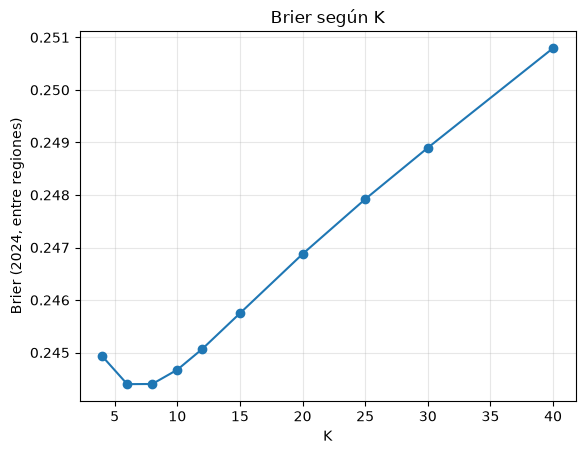

In [4]:
scores = [objective([seasons[2024]], Params(k=float(k))) for k in K_GRID]
plt.plot(K_GRID, scores, marker="o")
plt.xlabel("K"); plt.ylabel("Brier (2024, entre regiones)")
plt.title("Brier según K"); plt.grid(alpha=.3); plt.show()

## Calibrar con 2024
Búsqueda por coordenadas: se ajusta un parámetro por vez probando su grilla, se repite hasta que nada mejora.

In [5]:
tuned_2024, score_2024 = tune([seasons[2024]])
print(tuned_2024, f"Brier 2024 = {score_2024:.4f}")

Params(k=15.0, region_offsets={'KR': 350.0, 'CN': 350.0, 'EU': 200.0, 'NA': 200.0}) Brier 2024 = 0.2182


## Validar en 2025 (datos no vistos)
Si el Brier de 2025 empeora mucho respecto de 2024, los valores se ajustaron al ruido de 2024 (sobreajuste).

In [6]:
val_tuned = objective([seasons[2025]], tuned_2024)
val_base = objective([seasons[2025]], base)
print(f"2025: moneda 0.2500 | sin ajuste {val_base:.4f} | calibrado con 2024 {val_tuned:.4f}")

2025: moneda 0.2500 | sin ajuste 0.2349 | calibrado con 2024 0.2216


## Series de Worlds 2025
Lo que importa para el sitio: probabilidad de ganar la serie, calculada antes de cada serie.

In [7]:
games25, regions25 = seasons[2025]
run25 = run_elo(games25, tuned_2024, regions25)
matches25 = json.loads((RAW / "worlds_2025_matches.json").read_text(encoding="utf-8"))["rows"]
probs, outcomes = worlds_series(run25.records, matches25)
worlds = summarize(probs, outcomes)
print(f"Series: {worlds['n']} | aciertos {worlds['correct']} ({worlds['accuracy']:.0%}) | Brier {worlds['brier']:.4f}")
pd.DataFrame(worlds["calibration"])

Series: 41 | aciertos 29 (71%) | Brier 0.1871


,label,n,predicted,observed
0,50–60%,10,0.5297,0.5000
1,60–70%,8,0.6484,0.7500
2,70%+,23,0.8251,0.7826


## Gráfico de calibración (games entre regiones, 2025)
Cada punto es un tramo de probabilidad: si el modelo está bien calibrado, cae sobre la diagonal. El tamaño indica cuántos games hay en el tramo.

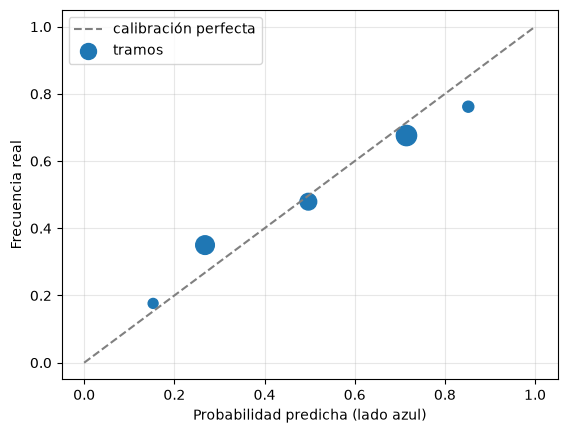

,predicho,real,n
tramo,,,
"(0.0, 0.2]",0.152900,0.176471,17
"(0.2, 0.4]",0.268053,0.350000,60
"(0.4, 0.6]",0.497201,0.479167,48
"(0.6, 0.8]",0.714810,0.676056,71
"(0.8, 1.0]",0.851911,0.761905,21


In [8]:
cross = cross_region_records(run25.records, regions25)
df = pd.DataFrame({"p": [r["p_blue"] for r in cross], "won": [r["blue_won"] for r in cross]})
df["tramo"] = pd.cut(df["p"], bins=[0, .2, .4, .6, .8, 1])
cal = df.groupby("tramo", observed=True).agg(predicho=("p", "mean"), real=("won", "mean"), n=("p", "size"))
plt.plot([0, 1], [0, 1], ls="--", color="gray", label="calibración perfecta")
plt.scatter(cal["predicho"], cal["real"], s=cal["n"] * 3, label="tramos")
plt.xlabel("Probabilidad predicha (lado azul)"); plt.ylabel("Frecuencia real")
plt.legend(); plt.grid(alpha=.3); plt.show()
cal

## Valores finales
Con la validación hecha, se recalibra con 2024 + 2025 juntos (más datos = valores más estables). La estimación honesta del error es la de la validación de arriba, no la de este ajuste.

In [9]:
final, final_score = tune([seasons[2024], seasons[2025]])
backtest = {
    "calibration_year": 2024, "validation_year": 2025,
    "validation_games": len(cross), "validation_brier": round(val_tuned, 4), "baseline_brier": round(val_base, 4),
    "worlds_series": worlds["n"], "worlds_accuracy": worlds["accuracy"], "worlds_brier": worlds["brier"],
}
print("PARAMS =", final)
print("BACKTEST =", backtest)

PARAMS = Params(k=10.0, region_offsets={'KR': 300.0, 'CN': 200.0, 'EU': 100.0, 'NA': 100.0})
BACKTEST = {'calibration_year': 2024, 'validation_year': 2025, 'validation_games': 217, 'validation_brier': 0.2216, 'baseline_brier': 0.2349, 'worlds_series': 41, 'worlds_accuracy': 0.7073, 'worlds_brier': 0.1871}


## Conclusiones

- **K = 10** (ajuste final): el rating se mueve poco después de cada game. Con ~100 games por equipo en la temporada, conviene un Elo estable que no persiga rachas.
- **Ajustes regionales** respecto de BR/APAC/el resto: **KR +300, CN +200, EU +100, NA +100**. Antes de jugar nada, un equipo coreano promedio tiene ~85% de ganarle un game a uno de APAC; los internacionales del año van corrigiendo eso.
- **Validación en 2025** (datos no vistos): Brier 0.2216 contra 0.2349 sin ajuste regional y 0.25 de la moneda. La mejora es real pero modesta: un game individual es muy ruidoso.
- **Series de Worlds 2025:** 29 de 41 aciertos (71%), Brier 0.187. En el tramo 70%+ el modelo predijo 83% de promedio y el favorito ganó el 78%: un poco sobreconfiado, pero con 23 series esa diferencia está dentro del ruido.
- **⚠️ Inestabilidad:** calibrado solo con 2024 da K = 15 con KR/CN +350 y EU/NA +200; con 2024 + 2025 da los valores de arriba. Que cambien tanto indica que los números exactos están poco determinados (muestra chica) y que la fuerza relativa de las regiones cambia de un año a otro. Hay que leerlos como aproximados, no como verdades.
